In [1]:
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from dotenv import load_dotenv
from langchain_unstructured import UnstructuredLoader
from langchain_text_splitters import CharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_pinecone import PineconeVectorStore
from sklearn.manifold import TSNE

load_dotenv()

/Users/kiranchand/Documents/Github/ai-llm/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [2]:
base_dir = "/Users/kiranchand/Documents/Github/ai-llm"
# doc_type -> file name
files = {
    "employee": "employees.txt",
    "product": "products.txt",
    "policy": "policy.txt",
}

documents = []
for doc_type, file_name in files.items():
    loader = UnstructuredLoader(
        file_path=f"{base_dir}/{file_name}",
        chunking_strategy="basic",
        max_characters=1000000,
    )
    for doc in loader.load():
        # Keep only the metadata we need. Unstructured also adds a large
        # "orig_elements" field that would be copied into every chunk.
        doc.metadata = {"source": file_name, "doc_type": doc_type}
        documents.append(doc)

print(f"loaded {len(documents)} documents from {len(files)} files")

INFO: Downloading spaCy model en_core_web_sm 3.8.0 …
INFO: Installed en_core_web_sm 3.8.0


loaded 3 documents from 3 files


In [3]:
print("splitting...")
text_splitter = CharacterTextSplitter(chunk_size=1000, chunk_overlap=50)
texts = text_splitter.split_documents(documents)  # each chunk keeps its file's metadata
print(f"created {len(texts)} chunks")
print(Counter(t.metadata["doc_type"] for t in texts))

splitting...
created 37 chunks
Counter({'policy': 14, 'employee': 13, 'product': 10})


In [5]:
print(texts[1])

page_content='EXECUTIVE LEADERSHIP TEAM

Margaret Ellison - Chief Executive Officer (CEO). Employee ID ACM-0001. Co-founder of Acme Corporation in 2008 and CEO since the company started. Before Acme, Margaret was a merchandising manager at a regional department store chain for nine years. She holds an MBA from the University of Colorado. Margaret reports to the Board of Directors and chairs the weekly executive leadership meeting every Monday at 9:00 AM. Email: margaret.ellison@acme-corp.example

Daniel Okafor - Chief Technology Officer (CTO). Employee ID ACM-0002. Co-founder of Acme. Daniel built the first version of the Acme website himself and led the move of Acme's platform to the cloud in 2019. He oversees engineering, data science, IT and information security. He holds a master's degree in computer science from Georgia Tech. Reports to Margaret Ellison. Email: daniel.okafor@acme-corp.example' metadata={'source': 'employees.txt', 'doc_type': 'employee'}


In [16]:
embeddings = OpenAIEmbeddings(  model="text-embedding-3-small",openai_api_key=os.environ.get("OPENAI_API_KEY"))

In [17]:
# Fixed IDs (e.g. "product-12") let us fetch the vectors back later,
# and re-running this cell overwrites the same vectors instead of adding duplicates.
ids = [f"{t.metadata['doc_type']}-{i}" for i, t in enumerate(texts)]

print("ingesting...")
vectorstore = PineconeVectorStore.from_documents(
    texts, embeddings, index_name=os.environ["INDEX_NAME"], ids=ids
)
print("finish")

ingesting...


INFO: HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"


finish


In [19]:
# Let's investigate the vectors

stats = vectorstore.index.describe_index_stats()
count = stats.total_vector_count
dimensions = stats.dimension
print(f"There are {count:,} vectors with {dimensions:,} dimensions in the vector store")

There are 37 vectors with 1,536 dimensions in the vector store


In [20]:
# Fetch the stored vectors and their metadata back from Pinecone
response = vectorstore.index.fetch(ids=ids)
fetched_ids = [i for i in ids if i in response.vectors]  # newly written vectors can take a few seconds to appear

vectors = np.array([response.vectors[i].values for i in fetched_ids])
doc_types = np.array([response.vectors[i].metadata["doc_type"] for i in fetched_ids])
print(f"fetched {len(vectors)} of {len(ids)} vectors, shape {vectors.shape}")

fetched 37 of 37 vectors, shape (37, 1536)


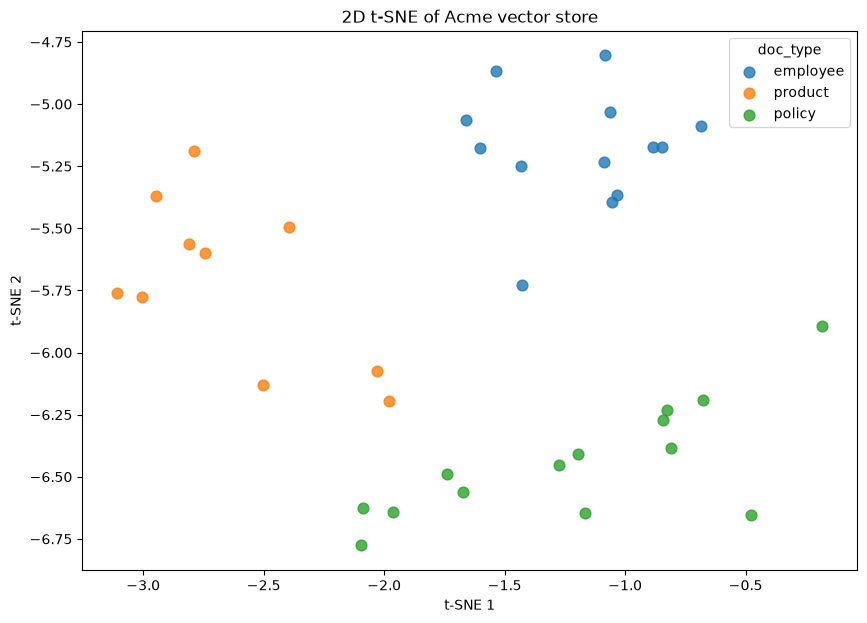

In [21]:
# Reduce the vectors to 2D with t-SNE and color each point by doc_type
tsne = TSNE(n_components=2, perplexity=min(30, len(vectors) - 1), random_state=42)
reduced = tsne.fit_transform(vectors)

colors = {"employee": "tab:blue", "product": "tab:orange", "policy": "tab:green"}

plt.figure(figsize=(10, 7))
for doc_type, color in colors.items():
    mask = doc_types == doc_type
    plt.scatter(reduced[mask, 0], reduced[mask, 1], c=color, label=doc_type, s=60, alpha=0.8)
plt.title("2D t-SNE of Acme vector store")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="doc_type")
plt.show()